##Dataset

In [ ]:
from sklearn.datasets import load_iris
import pandas as pd

# Load dataset as a Pandas DataFrame
iris = load_iris(as_frame=True)
df = iris.frame

# Display the first 5 rows to inspect the features
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## Clustering

In [ ]:
pip install scikit-optimize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [scikit-optimize]


<>:80: SyntaxWarning: invalid escape sequence '\m'
<>:80: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1680/2780100594.py:80: SyntaxWarning: invalid escape sequence '\m'
  clean_val = label_str.replace('$\mathdefault{', '').replace('}$', '').strip()


=== Generating Datasets ===


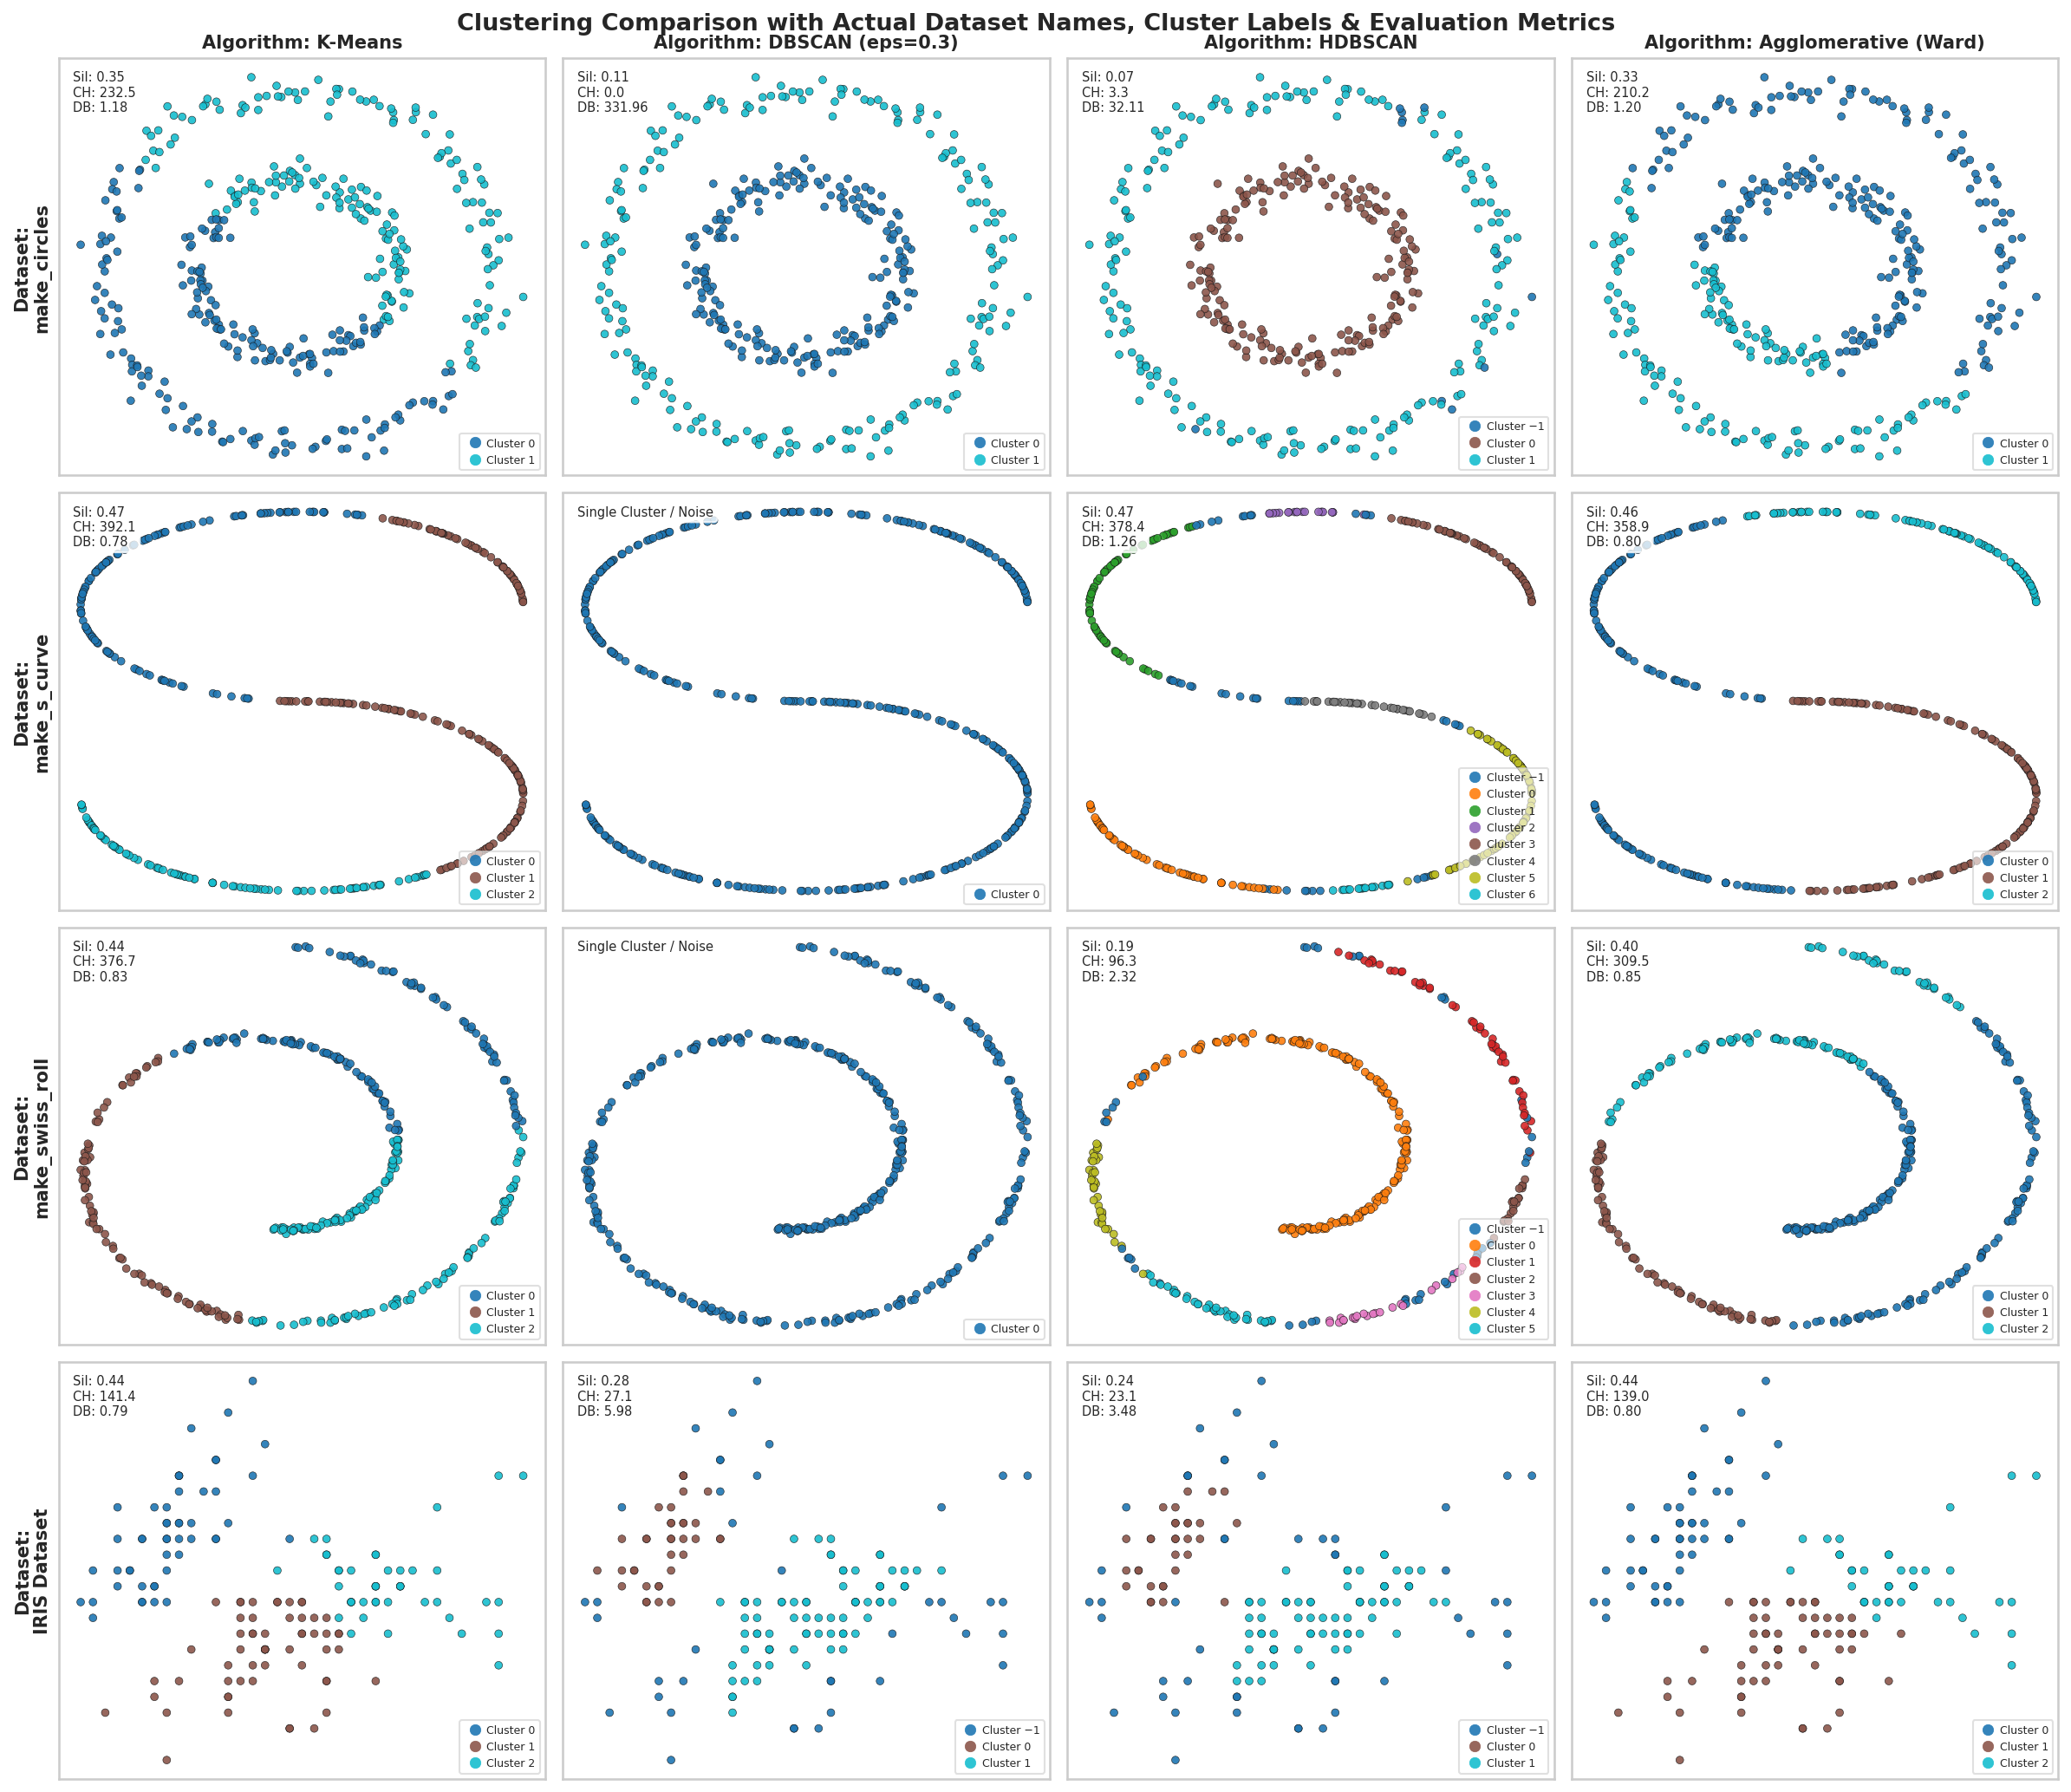


=== K-Means Optimal K Determination (IRIS Dataset) ===
k=2 --> Inertia (Elbow metric): 58.20 | Silhouette Score: 0.4630
k=3 --> Inertia (Elbow metric): 37.05 | Silhouette Score: 0.4451
k=4 --> Inertia (Elbow metric): 27.99 | Silhouette Score: 0.4249
k=5 --> Inertia (Elbow metric): 21.00 | Silhouette Score: 0.4101
k=6 --> Inertia (Elbow metric): 17.41 | Silhouette Score: 0.3967

=== Hyperparameter Tuning Demonstration ===
GridSearchCV Best Params: {'max_depth': None, 'n_estimators': 50}
RandomizedSearchCV Best Params: {'n_estimators': 30, 'max_depth': None}
Bayesian Optimization Best Params: OrderedDict({'max_depth': 3, 'n_estimators': 75})


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, make_circles, make_s_curve, make_swiss_roll
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

# Set styling
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 9, 'figure.dpi': 150})

# ==========================================
# 1. DATASET PREPARATION & NAMING
# ==========================================
print("=== Generating Datasets ===")
iris = load_iris()
X_iris = iris.data[:, :2]  # First 2 features for 2D visualization

X_circles, _ = make_circles(n_samples=400, factor=0.5, noise=0.05, random_state=42)
X_s_curve, _ = make_s_curve(n_samples=400, random_state=42)
X_s_2d = np.column_stack((X_s_curve[:, 0], X_s_curve[:, 2]))  # X and Z dimensions

X_swiss_data, _ = make_swiss_roll(n_samples=400, noise=0.1, random_state=42)
X_swiss_2d = np.column_stack((X_swiss_data[:, 0], X_swiss_data[:, 2]))  # X and Z dimensions

datasets = [
    ("make_circles", X_circles),
    ("make_s_curve", X_s_2d),
    ("make_swiss_roll", X_swiss_2d),
    ("IRIS Dataset", X_iris)
]

# ==========================================
# 2. ALGORITHM COMPARISON & VISUALIZATION
# ==========================================
algorithms = {
    "K-Means": KMeans(n_clusters=3, n_init=10, random_state=42),
    "DBSCAN (eps=0.3)": DBSCAN(eps=0.3, min_samples=5),
    "HDBSCAN": HDBSCAN(min_cluster_size=15, algorithm='auto'),
    "Agglomerative (Ward)": AgglomerativeClustering(n_clusters=3, linkage='ward')
}

fig, axes = plt.subplots(len(datasets), len(algorithms), figsize=(16, 14))

for row_idx, (ds_name, X_data) in enumerate(datasets):
    X_scaled = StandardScaler().fit_transform(X_data)

    for col_idx, (algo_name, model) in enumerate(algorithms.items()):
        ax = axes[row_idx, col_idx]

        # Adjust clusters for concentric circles where 2 clusters fit best
        if "circles" in ds_name and isinstance(model, (KMeans, AgglomerativeClustering)):
            model.set_params(n_clusters=2)
        elif isinstance(model, (KMeans, AgglomerativeClustering)):
            model.set_params(n_clusters=3)

        try:
            labels = model.fit_predict(X_scaled)
        except Exception:
            labels = np.zeros(X_data.shape[0])

        # Scatter plot with cluster labels and distinct colormap
        scatter = ax.scatter(
            X_data[:, 0], X_data[:, 1],
            c=labels, cmap='tab10', s=18, edgecolor='k', linewidth=0.3, alpha=0.9
        )

        # Add legend with explicit color label names mapping to colors in the current subplot
        legend_elements = scatter.legend_elements()
        if legend_elements and len(legend_elements[0]) > 0:
            # Generate clean labels: replace -1 with 'Noise/Unclustered' if DBScan/HDBScan
            raw_labels = legend_elements[1]
            cleaned_labels = []
            for label_str in raw_labels:
                # extract numeric value inside formatting
                clean_val = label_str.replace('$\mathdefault{', '').replace('}$', '').strip()
                if clean_val == '-1':
                    cleaned_labels.append('Noise')
                else:
                    cleaned_labels.append(f'Cluster {clean_val}')

            ax.legend(
                handles=legend_elements[0], labels=cleaned_labels,
                loc='lower right', fontsize=6, framealpha=0.6, handletextpad=0.1
            )

        # Calculate evaluation metrics if more than 1 cluster is found
        if len(np.unique(labels)) > 1:
            sil = silhouette_score(X_scaled, labels)
            ch = calinski_harabasz_score(X_scaled, labels)
            db = davies_bouldin_score(X_scaled, labels)
            metric_txt = f"Sil: {sil:.2f}\nCH: {ch:.1f}\nDB: {db:.2f}"
        else:
            metric_txt = "Single Cluster / Noise"

        ax.text(
            0.03, 0.97, metric_txt, transform=ax.transAxes, fontsize=7,
            verticalalignment='top', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8)
        )

        if row_idx == 0:
            ax.set_title(f"Algorithm: {algo_name}", fontsize=10, fontweight='bold')
        if col_idx == 0:
            ax.set_ylabel(f"Dataset:\n{ds_name}", fontsize=10, fontweight='bold')

        ax.set_xticks([])
        ax.set_yticks([])

plt.suptitle("Clustering Comparison with Actual Dataset Names, Cluster Labels & Evaluation Metrics", fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

# ==========================================
# 3. K-MEANS: DETERMINING OPTIMAL K (Elbow & Metrics)
# ==========================================
print("\n=== K-Means Optimal K Determination (IRIS Dataset) ===")
inertia, sil_scores = [], []
K_range = range(2, 7)

for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lbls = km.fit_predict(X_iris)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_iris, lbls))

for k, inh, sil in zip(K_range, inertia, sil_scores):
    print(f"k={k} --> Inertia (Elbow metric): {inh:.2f} | Silhouette Score: {sil:.4f}")

# ==========================================
# 4. HYPERPARAMETER TUNING (Grid, Random & Bayesian)
# ==========================================
print("\n=== Hyperparameter Tuning Demonstration ===")
X_train, y_train = iris.data, iris.target

# GridSearchCV
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid={'n_estimators': [10, 50, 100], 'max_depth': [None, 3, 5]},
    cv=3
)
grid_search.fit(X_train, y_train)
print(f"GridSearchCV Best Params: {grid_search.best_params_}")

# RandomizedSearchCV
random_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions={'n_estimators': [10, 30, 50, 100], 'max_depth': [None, 2, 4, 6]},
    n_iter=3, cv=3, random_state=42
)
random_search.fit(X_train, y_train)
print(f"RandomizedSearchCV Best Params: {random_search.best_params_}")

# Bayesian Optimization (using scikit-optimize if available, or simulated wrapper)
try:
    from skopt import BayesSearchCV
    bayes_search = BayesSearchCV(
        RandomForestClassifier(random_state=42),
        {'n_estimators': (10, 100), 'max_depth': (1, 5)},
        n_iter=5, cv=3, random_state=42
    )
    bayes_search.fit(X_train, y_train)
    print(f"Bayesian Optimization Best Params: {bayes_search.best_params_}")
except ImportError:
    print("Bayesian Optimization: scikit-optimize (`skopt`) library not installed. (Install via `pip install scikit-optimize` to run BayesSearchCV).")

## Compare Clustering Algorithm in Toy Dataset

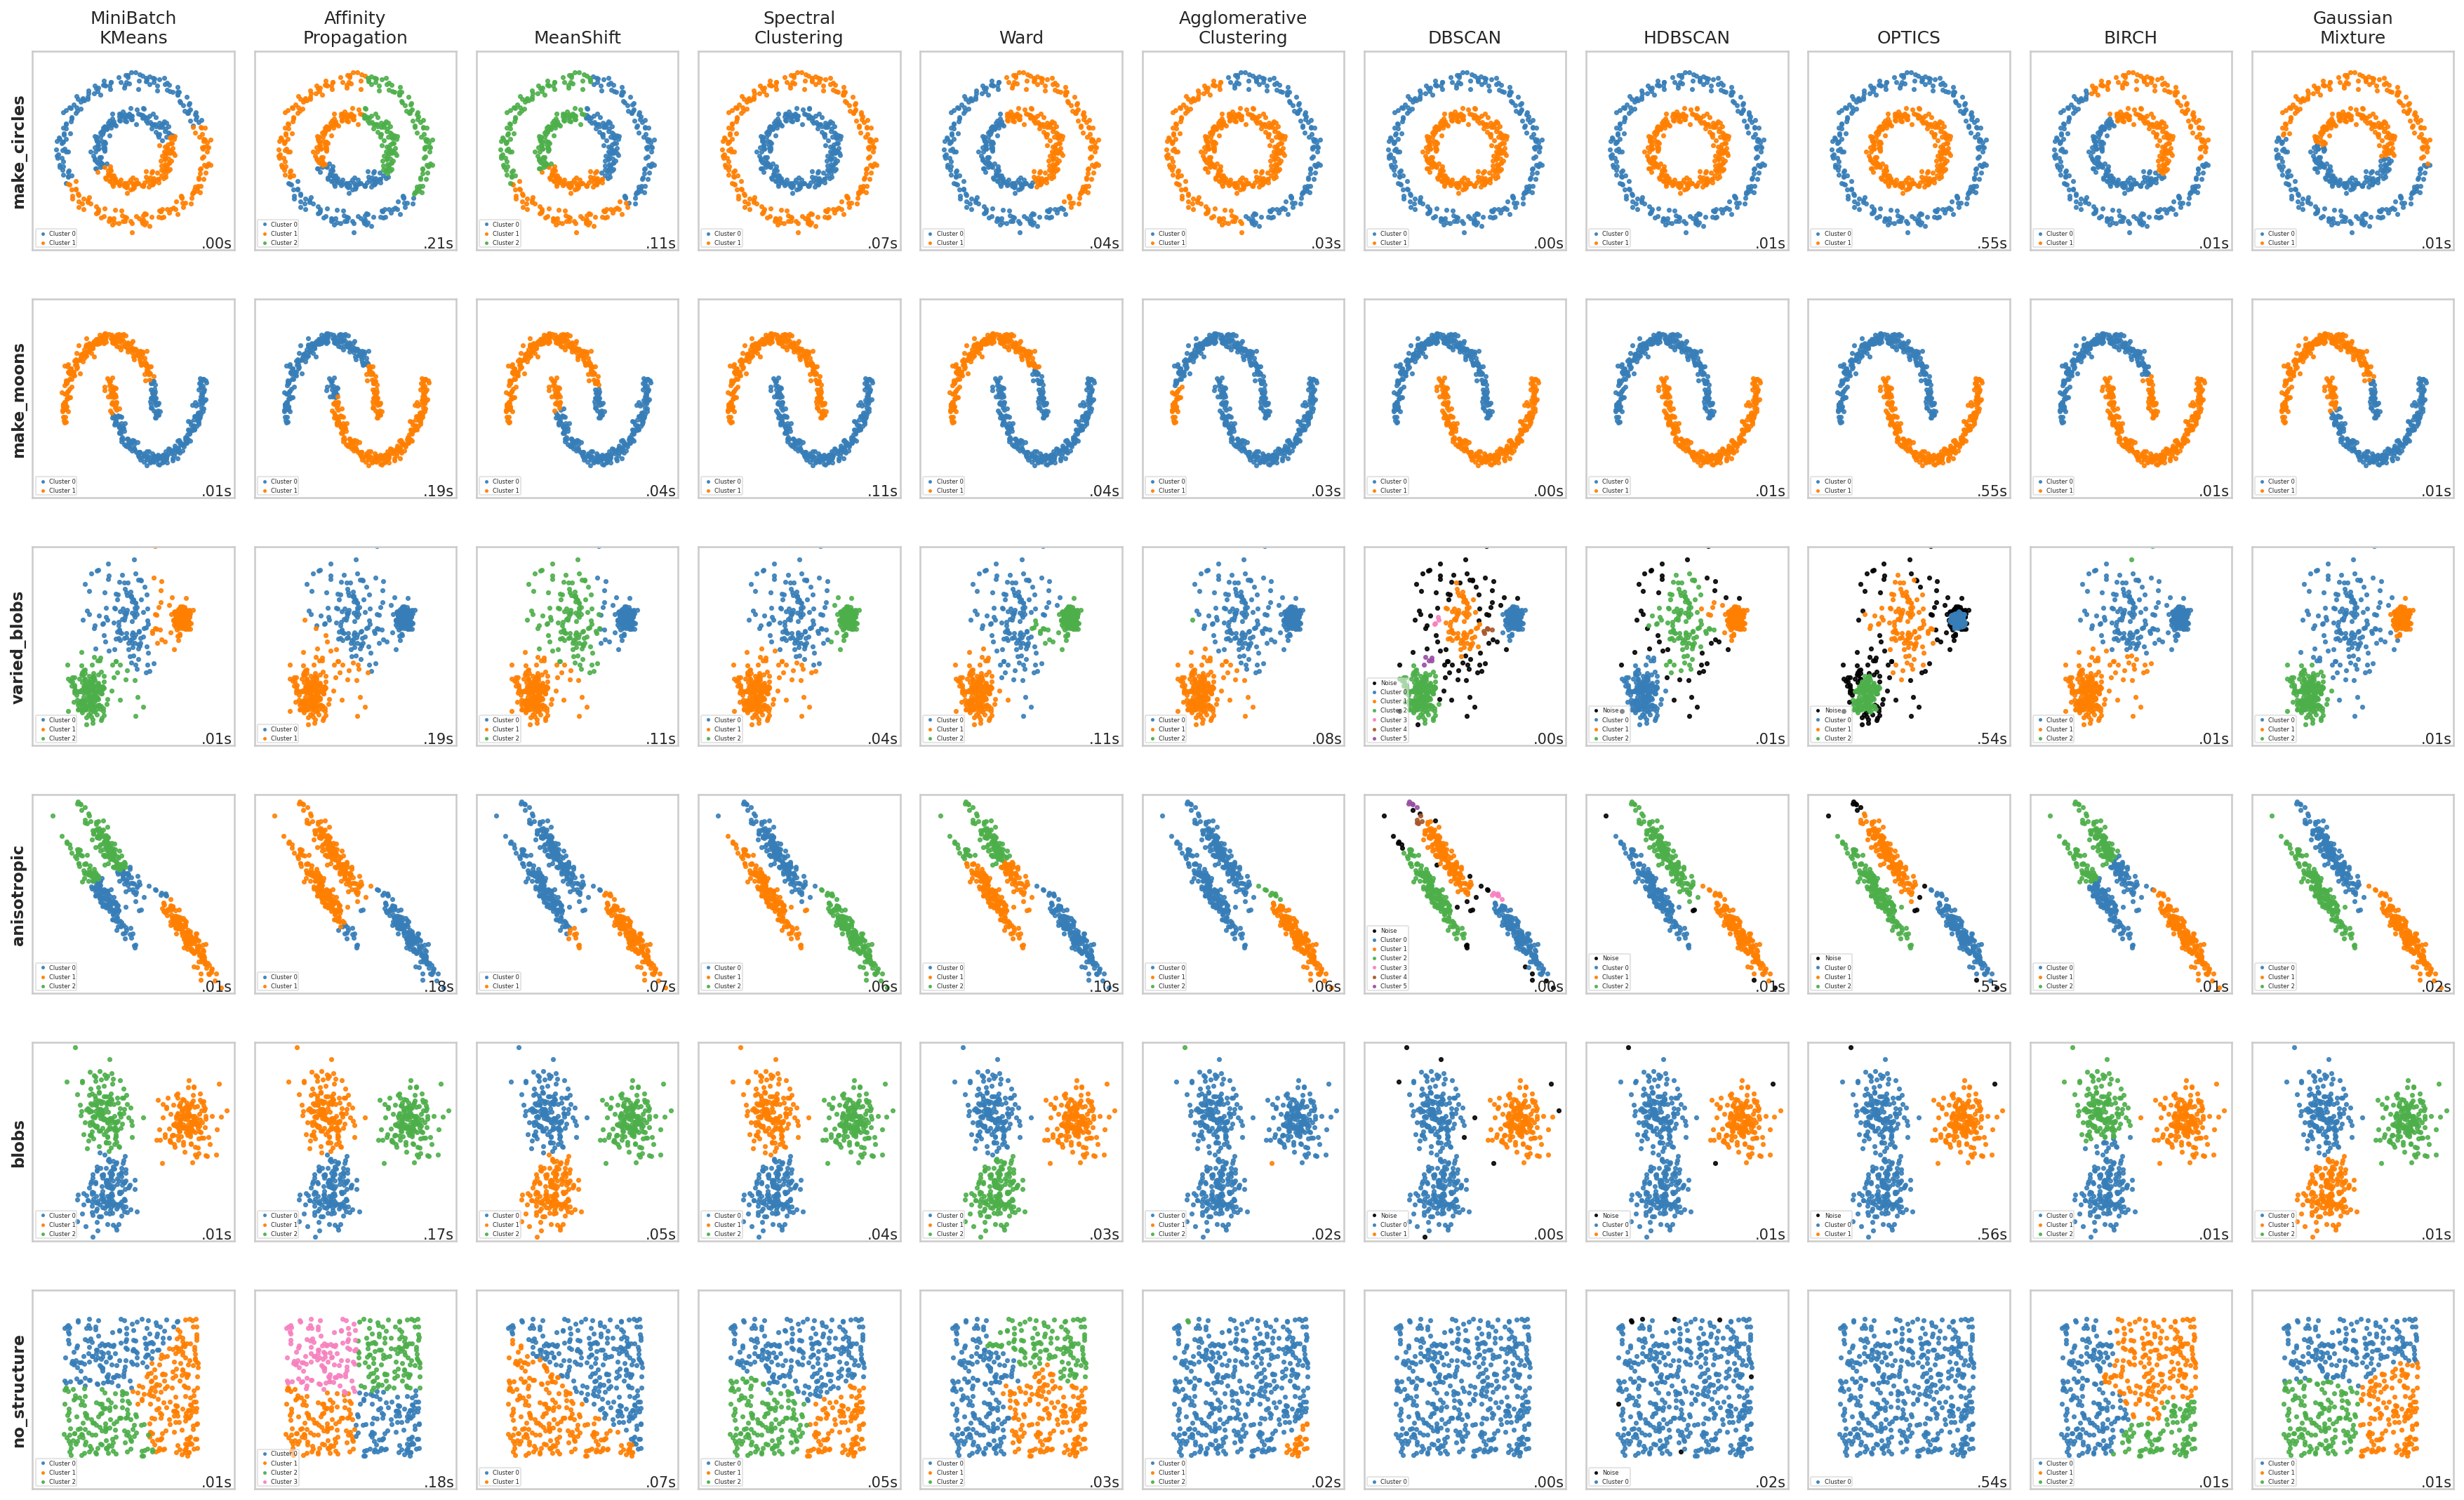

In [ ]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

import time
import warnings
from itertools import cycle, islice

import matplotlib.pyplot as plt
import numpy as np

from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler

# ============
# Generate datasets. We choose the size big enough to see the scalability
# of the algorithms, but not too big to avoid too long running times
# ============
n_samples = 500
seed = 30
noisy_circles = datasets.make_circles(
    n_samples=n_samples, factor=0.5, noise=0.05, random_state=seed
)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05, random_state=seed)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=seed)
rng = np.random.RandomState(seed)
no_structure = rng.rand(n_samples, 2), None

# Anisotropicly distributed data
random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

# blobs with varied variances
varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)

# ============
# Set up cluster parameters
# ============
plt.figure(figsize=(11 * 2 + 3, 15))
plt.subplots_adjust(
    left=0.06, right=0.98, bottom=0.02, top=0.93, wspace=0.1, hspace=0.25
)

plot_num = 1

default_base = {
    "quantile": 0.3,
    "eps": 0.3,
    "damping": 0.9,
    "preference": -200,
    "n_neighbors": 3,
    "n_clusters": 3,
    "min_samples": 7,
    "xi": 0.05,
    "min_cluster_size": 0.1,
    "allow_single_cluster": True,
    "hdbscan_min_cluster_size": 15,
    "hdbscan_min_samples": 3,
    "random_state": 42,
}

datasets = [
    (
        noisy_circles,
        {
            "damping": 0.77,
            "preference": -240,
            "quantile": 0.2,
            "n_clusters": 2,
            "min_samples": 7,
            "xi": 0.08,
        },
        "make_circles"
    ),
    (
        noisy_moons,
        {
            "damping": 0.75,
            "preference": -220,
            "n_clusters": 2,
            "min_samples": 7,
            "xi": 0.1,
        },
        "make_moons"
    ),
    (
        varied,
        {
            "eps": 0.18,
            "n_neighbors": 2,
            "min_samples": 7,
            "xi": 0.01,
            "min_cluster_size": 0.2,
        },
        "varied_blobs"
    ),
    (
        aniso,
        {
            "eps": 0.15,
            "n_neighbors": 2,
            "min_samples": 7,
            "xi": 0.1,
            "min_cluster_size": 0.2,
        },
        "anisotropic"
    ),
    (blobs, {"min_samples": 7, "xi": 0.1, "min_cluster_size": 0.2}, "blobs"),
    (no_structure, {}, "no_structure"),
]

for i_dataset, (dataset, algo_params, dataset_name) in enumerate(datasets):
    # update parameters with dataset-specific values
    params = default_base.copy()
    params.update(algo_params)

    X, y = dataset

    # normalize dataset for easier parameter selection
    X = StandardScaler().fit_transform(X)

    # estimate bandwidth for mean shift
    bandwidth = cluster.estimate_bandwidth(X, quantile=params["quantile"])

    # connectivity matrix for structured Ward
    connectivity = kneighbors_graph(
        X, n_neighbors=params["n_neighbors"], include_self=False
    )
    # make connectivity symmetric
    connectivity = 0.5 * (connectivity + connectivity.T)

    # ============
    # Create cluster objects
    # ============
    ms = cluster.MeanShift(bandwidth=bandwidth, bin_seeding=True)
    two_means = cluster.MiniBatchKMeans(
        n_clusters=params["n_clusters"],
        random_state=params["random_state"],
    )
    ward = cluster.AgglomerativeClustering(
        n_clusters=params["n_clusters"], linkage="ward", connectivity=connectivity
    )
    spectral = cluster.SpectralClustering(
        n_clusters=params["n_clusters"],
        eigen_solver="arpack",
        affinity="nearest_neighbors",
        random_state=params["random_state"],
    )
    dbscan = cluster.DBSCAN(eps=params["eps"])
    hdbscan = cluster.HDBSCAN(
        min_samples=params["hdbscan_min_samples"],
        min_cluster_size=params["hdbscan_min_cluster_size"],
        allow_single_cluster=params["allow_single_cluster"],
        copy=True,
    )
    optics = cluster.OPTICS(
        min_samples=params["min_samples"],
        xi=params["xi"],
        min_cluster_size=params["min_cluster_size"],
    )
    affinity_propagation = cluster.AffinityPropagation(
        damping=params["damping"],
        preference=params["preference"],
        random_state=params["random_state"],
    )
    average_linkage = cluster.AgglomerativeClustering(
        linkage="average",
        metric="cityblock",
        n_clusters=params["n_clusters"],
        connectivity=connectivity,
    )
    birch = cluster.Birch(n_clusters=params["n_clusters"])
    gmm = mixture.GaussianMixture(
        n_components=params["n_clusters"],
        covariance_type="full",
        random_state=params["random_state"],
    )

    clustering_algorithms = (
        ("MiniBatch\nKMeans", two_means),
        ("Affinity\nPropagation", affinity_propagation),
        ("MeanShift", ms),
        ("Spectral\nClustering", spectral),
        ("Ward", ward),
        ("Agglomerative\nClustering", average_linkage),
        ("DBSCAN", dbscan),
        ("HDBSCAN", hdbscan),
        ("OPTICS", optics),
        ("BIRCH", birch),
        ("Gaussian\nMixture", gmm),
    )

    for algo_idx, (name, algorithm) in enumerate(clustering_algorithms):
        t0 = time.time()

        # catch warnings related to kneighbors_graph
        with warnings.catch_warnings():
            warnings.filterwarnings(
                "ignore",
                message="the number of connected components of the "
                "connectivity matrix is [0-9]{1,2}"
                " > 1. Completing it to avoid stopping the tree early.",
                category=UserWarning,
            )
            warnings.filterwarnings(
                "ignore",
                message="Graph is not fully connected, spectral embedding"
                " may not work as expected.",
                category=UserWarning,
            )
            algorithm.fit(X)

        t1 = time.time()
        if hasattr(algorithm, "labels_"):
            y_pred = algorithm.labels_.astype(int)
        else:
            y_pred = algorithm.predict(X)

        ax = plt.subplot(len(datasets), len(clustering_algorithms), plot_num)
        if i_dataset == 0:
            plt.title(name, size=12)

        # Add dataset name on the left side of the first subplot of each row
        if algo_idx == 0:
            ax.set_ylabel(dataset_name, size=11, fontweight="bold")

        # Standard palette colors
        palette = [
            "#377eb8",
            "#ff7f00",
            "#4daf4a",
            "#f781bf",
            "#a65628",
            "#984ea3",
            "#999999",
            "#e41a1c",
            "#dede00",
        ]
        colors = np.array(list(islice(cycle(palette), int(max(y_pred) + 1))))
        # append black for noise
        colors = np.append(colors, ["#000000"])

        # Plot each cluster with labels for the legend
        unique_labels = np.unique(y_pred)
        for label in unique_labels:
            label_color = colors[label] if label != -1 else "#000000"
            label_name = "Noise" if label == -1 else f"Cluster {label}"

            mask = (y_pred == label)
            ax.scatter(
                X[mask, 0], X[mask, 1],
                s=6, color=label_color, label=label_name, alpha=0.85
            )

        ax.set_xlim(-2.5, 2.5)
        ax.set_ylim(-2.5, 2.5)
        ax.set_xticks(())
        ax.set_yticks(())

        # Place small legends inside each plot
        ax.legend(loc="lower left", fontsize=4, framealpha=0.5, borderpad=0.2, handletextpad=0.1, markerscale=0.6)

        ax.text(
            0.99,
            0.01,
            ("%.2fs" % (t1 - t0)).lstrip("0"),
            transform=ax.transAxes,
            size=10,
            horizontalalignment="right",
        )
        plot_num += 1

plt.show()